# Parte 1 (Stages D–G) e Parte 2 (Stages H–I)

Continuação do `1_handcraft_stagesABC.ipynb`, com o mesmo protocolo:

- **treino / validação**: o subset `"train"` dos ficheiros, dividido 80/20 (estratificado, seed 42);
- **teste**: o subset `"val"` dos ficheiros, usado **uma única vez** por configuração final;
- **escolhas** (normalização, kernel, pipeline do VLAD/FV) feitas sempre pelo **AP na validação**;
- **modelo final** treinado com treino + validação antes de ir ao teste;
- **C = 10** fixo, como o enunciado permite (nota da Stage F); a Stage F verifica que o efeito de C é pequeno.

Categorias do dataset: aeroplane, motorbike, person (horse e car não existem; o código salta-as).

**AP:** `sklearn.metrics.average_precision_score`, soma de degraus Σ(Rₙ − Rₙ₋₁)·Pₙ, **sem interpolação**;
classe positiva = a categoria, negativa = background.

In [1]:
import os
import time
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.metrics import average_precision_score, PrecisionRecallDisplay
from sklearn.model_selection import train_test_split

from src import utils, encoders
from src.visualization import displayPrecisionRecallCurve

SEED = 42
C = 10
CANDIDATE_CATEGORIES = ["aeroplane", "motorbike", "person", "horse", "car"]

# O enunciado pede para registar hardware e versões
print("Python:", platform.python_version(), "| NumPy:", np.__version__, "| scikit-learn:", sklearn.__version__)
print("CPU:", platform.processor() or platform.machine(), "| núcleos:", os.cpu_count())

Python: 3.11.17 | NumPy: 2.4.6 | scikit-learn: 1.9.1
CPU: AMD64 Family 25 Model 117 Stepping 2, AuthenticAMD | núcleos: 16


## Funções comuns

- `load_data`: carrega uma (categoria, encoding) e faz o split treino/validação/teste.
- `preprocess`: aplica uma **lista de passos** pela ordem dada, por exemplo `["sqrt", "l2"]`.
  Assim cada configuração experimental é só uma lista, e a ordem das operações fica explícita
  (é exatamente o que a pergunta da Stage F pede para estudar).
- `validation_ap`: treina no treino e mede o AP na validação (para **escolher**).
- `test_ap`: treina com treino + validação e mede o AP no teste (para **reportar**).

In [2]:
def loadEncodingSubset(category, encoding, subset="train", root_dir="data"):
    base_dir = f"{root_dir}/encodings/{encoding}/"
    p_data = np.load(f"{base_dir}/{category}_{subset}.npz")
    n_data = np.load(f"{base_dir}/background_{subset}.npz")

    hist = np.concatenate([p_data["histograms"], n_data["histograms"]], axis=0)
    names = np.concatenate([p_data["file_names"], n_data["file_names"]], axis=0)
    labels = np.concatenate([np.ones(len(p_data["file_names"]), dtype=np.int32),
                             -np.ones(len(n_data["file_names"]), dtype=np.int32)])
    return hist, labels, names


def category_exists(category, encoding="bovw_K512_C0"):
    return os.path.exists(f"data/encodings/{encoding}/{category}_train.npz")


def load_data(category, encoding, val_fraction=0.2, seed=SEED):
    x, y, names = loadEncodingSubset(category, encoding, subset="train")
    x_test, y_test, names_test = loadEncodingSubset(category, encoding, subset="val")

    # float32 chega para o SVM e gasta metade da memória do float64 (importante no FV, ~20 000 dimensões)
    x, x_test = x.astype(np.float32), x_test.astype(np.float32)

    x_train, x_val, y_train, y_val, names_train, names_val = train_test_split(
        x, y, names, test_size=val_fraction, stratify=y, random_state=seed)

    return {"x_train": x_train, "y_train": y_train, "names_train": names_train,
            "x_val": x_val, "y_val": y_val, "names_val": names_val,
            "x_test": x_test, "y_test": y_test, "names_test": names_test}


# --- Passos de pré-processamento -------------------------------------------------

def l1norm(x):
    return x / (np.sum(np.abs(x), axis=1, keepdims=True) + 1e-10)


def l2norm(x):
    return x / (np.sqrt(np.sum(x**2, axis=1, keepdims=True)) + 1e-10)


def signed_sqrt(x):
    # Para o BoVW (valores >= 0) é igual a np.sqrt; o sinal só importa no VLAD e no FV.
    return np.sign(x) * np.sqrt(np.abs(x))


def remove_spatial_information(x, num_tiles=4):
    # Layout de encode_tiling: [tile0 | tile1 | tile2 | tile3] -> média dos 4 tiles
    return x.reshape(x.shape[0], num_tiles, -1).mean(axis=1)


def intra_normalize(x, block_size):
    # VLAD: normaliza com L2 cada bloco de resíduos (um bloco = um centro, block_size = D)
    blocks = x.reshape(x.shape[0], -1, block_size)
    blocks = blocks / (np.linalg.norm(blocks, axis=2, keepdims=True) + 1e-10)
    return blocks.reshape(x.shape[0], -1)


def preprocess(x, steps, block_size=None):
    for step in steps:
        if step == "global":
            x = remove_spatial_information(x)
        elif step == "l1":
            x = l1norm(x)
        elif step == "l2":
            x = l2norm(x)
        elif step == "sqrt":
            x = signed_sqrt(x)
        elif step == "intra":
            x = intra_normalize(x, block_size)
        else:
            raise ValueError(f"Passo desconhecido: {step}")
    return x


# --- Treino e avaliação -----------------------------------------------------------

def validation_ap(data, steps, C=C, block_size=None):
    """Treina no treino, avalia na validação. Devolve (AP, tempo de treino em s, dimensão)."""
    x_train = preprocess(data["x_train"], steps, block_size)
    x_val = preprocess(data["x_val"], steps, block_size)

    start = time.perf_counter()
    W, b = utils.train_svm(x_train, data["y_train"], C=C)
    train_time = time.perf_counter() - start

    ap = average_precision_score(data["y_val"], W @ x_val.T + b)
    return ap, train_time, x_train.shape[1]


def test_ap(data, steps, C=C, block_size=None):
    """Modelo final (treino + validação), avaliado uma vez no teste."""
    x_final = preprocess(np.concatenate([data["x_train"], data["x_val"]]), steps, block_size)
    y_final = np.concatenate([data["y_train"], data["y_val"]])
    x_test = preprocess(data["x_test"], steps, block_size)

    start = time.perf_counter()
    W, b = utils.train_svm(x_final, y_final, C=C)
    train_time = time.perf_counter() - start

    start = time.perf_counter()
    scores = W @ x_test.T + b
    inference_ms = (time.perf_counter() - start) * 1000 / len(x_test)

    ap = average_precision_score(data["y_test"], scores)
    return {"ap": ap, "scores": scores, "train_time": train_time, "inference_ms": inference_ms}


categories = [c for c in CANDIDATE_CATEGORIES if category_exists(c)]
print("Categorias disponíveis:", categories)

Categorias disponíveis: ['aeroplane', 'motorbike', 'person']


# Stage D: Other categories

Mesmo pipeline das Stages A–C (BoVW K=512, tiling 2×2, L2, C=10) para cada categoria.

A coluna **AP aleatório** é a fração de positivos no teste: é o AP esperado de um ranking ao acaso.
Sem ela não se consegue comparar classes. Para *person* há quase tantos positivos como negativos,
por isso o AP aleatório ronda 0,5, enquanto para *aeroplane* e *motorbike* ronda 0,1.

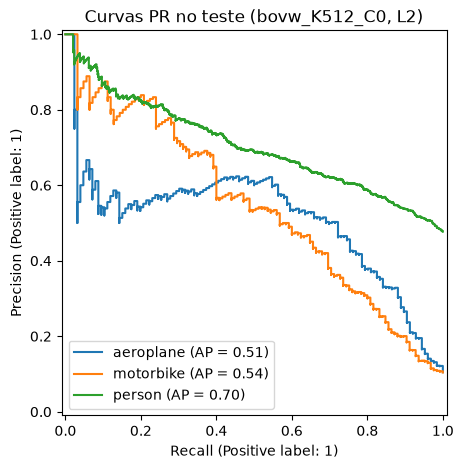

mAP teste: 0.5865


,categoria,positivos treino+val,positivos teste,AP aleatório,AP validação,AP teste
0,aeroplane,112,126,0.105,0.6236,0.5107
1,motorbike,120,125,0.104,0.5191,0.5440
2,person,1025,983,0.477,0.7123,0.7047


In [3]:
encoding = "bovw_K512_C0"
steps = ["l2"]

rows = []
fig, ax = plt.subplots(figsize=(6, 5))

for category in categories:
    data = load_data(category, encoding)
    ap_val, _, _ = validation_ap(data, steps)
    result = test_ap(data, steps)

    rows.append({
        "categoria": category,
        "positivos treino+val": int(np.sum(np.concatenate([data["y_train"], data["y_val"]]) > 0)),
        "positivos teste": int(np.sum(data["y_test"] > 0)),
        "AP aleatório": round(np.mean(data["y_test"] > 0), 3),
        "AP validação": round(ap_val, 4),
        "AP teste": round(result["ap"], 4),
    })
    PrecisionRecallDisplay.from_predictions(data["y_test"], result["scores"], ax=ax, name=category)

ax.set_title(f"Curvas PR no teste ({encoding}, L2)")
plt.show()

stage_d = pd.DataFrame(rows)
print(f"mAP teste: {stage_d['AP teste'].mean():.4f}")
stage_d

# Stage E: Normalization and spatial information

Para cada categoria comparam-se, **na validação**:
- normalização: nenhuma, L1, L2;
- representação: tiling 2×2 vs histograma global.

O passo `"global"` vem sempre **antes** da normalização, para que o vetor final tenha a norma pedida.

In [4]:
normalizations = {"nenhuma": [], "L1": ["l1"], "L2": ["l2"]}

rows = []
for category in categories:
    data = load_data(category, "bovw_K512_C0")
    for representation, spatial_steps in [("tiling 2x2", []), ("global", ["global"])]:
        for norm_name, norm_steps in normalizations.items():
            ap, train_time, dim = validation_ap(data, spatial_steps + norm_steps)
            rows.append({"categoria": category, "representação": representation,
                         "normalização": norm_name, "dimensão": dim,
                         "AP validação": round(ap, 4), "treino (s)": round(train_time, 2)})

stage_e = pd.DataFrame(rows)
stage_e.pivot_table(index=["categoria", "representação"], columns="normalização", values="AP validação")

normalização                 L1      L2  nenhuma
categoria representação                         
aeroplane global         0.7089  0.5363   0.6098
          tiling 2x2     0.7008  0.6236   0.7052
motorbike global         0.5134  0.6798   0.5279
          tiling 2x2     0.5442  0.5191   0.4983
person    global         0.6605  0.7406   0.6696
          tiling 2x2     0.5920  0.7123   0.6662

## Stage E: evidência para as perguntas sobre auto-semelhança

Para cada normalização calcula-se a matriz de kernel linear K = X·Xᵀ nas imagens de validação e verifica-se:
- se K(h, h) é constante (mín = máx);
- em que percentagem das imagens existe outra imagem h' com **K(h, h') > K(h, h)**,
  ou seja, uma imagem "mais parecida com outra do que consigo própria".

Pela teoria (Cauchy-Schwarz), com L2 a percentagem deve ser 0 e K(h, h) = 1.

In [5]:
def self_similarity_report(x):
    kernel = x @ x.T
    self_sim = np.diag(kernel).copy()

    others = kernel.copy()
    np.fill_diagonal(others, -np.inf)              # ignora a própria imagem
    beaten = others.max(axis=1) > self_sim + 1e-6   # 1e-6: tolerância para erros de arredondamento

    return {"K(h,h) mín": self_sim.min(), "K(h,h) máx": self_sim.max(),
            "% imagens com K(h,h') > K(h,h)": round(100 * beaten.mean(), 1)}


data = load_data("motorbike", "bovw_K512_C0")
pd.DataFrame({name: self_similarity_report(preprocess(data["x_val"], steps))
              for name, steps in normalizations.items()}).T

,"K(h,h) mín","K(h,h) máx","% imagens com K(h,h') > K(h,h)"
nenhuma,1.027445e+06,2.024455e+08,80.3
L1,1.122018e-03,1.787166e-01,79.4
L2,9.999968e-01,1.000004e+00,0.0


# Stage F: Hellinger feature map

O kernel de Hellinger K(h, h') = Σ √(hᵢ h'ᵢ) para histogramas L1 é um produto interno entre √h e √h'.
Logo, um SVM **linear** sobre √h é um SVM com kernel de Hellinger (feature map explícito).

No notebook original, a linha a acrescentar no sítio marcado (antes do `l2norm` que já lá está) é:

```python
histograms = np.sign(histograms) * np.sqrt(np.abs(histograms))
testHistograms = np.sign(testHistograms) * np.sqrt(np.abs(testHistograms))
```

Aqui comparam-se várias **ordens** de operações, para responder à pergunta "normalizar antes ou depois da raiz?".

In [6]:
hellinger_variants = {
    "Linear + L2 (referência)": ["l2"],
    "√ sem normalização": ["sqrt"],
    "L1 → √ (Hellinger clássico)": ["l1", "sqrt"],
    "√ → L2": ["sqrt", "l2"],
    "L2 → √": ["l2", "sqrt"],
    "√ → L1": ["sqrt", "l1"],
}

rows = []
for category in categories:
    data = load_data(category, "bovw_K512_C0")
    for name, steps in hellinger_variants.items():
        ap, _, _ = validation_ap(data, steps)
        rows.append({"categoria": category, "variante": name, "AP validação": round(ap, 4)})

stage_f = pd.DataFrame(rows)
stage_f.pivot_table(index="variante", columns="categoria", values="AP validação", sort=False)

categoria,aeroplane,motorbike,person
variante,,,
Linear + L2 (referência),0.6236,0.5191,0.7123
√ sem normalização,0.7424,0.6406,0.7510
L1 → √ (Hellinger clássico),0.7654,0.6956,0.7569
√ → L2,0.7654,0.6956,0.7569
L2 → √,0.7168,0.6862,0.7257
√ → L1,0.5901,0.5689,0.6098


**Verificação numérica:** L1 → √ e √ → L2 devem dar **exatamente** o mesmo vetor,
porque ‖√h‖₂² = Σ hᵢ = ‖h‖₁ para h ≥ 0.

In [7]:
data = load_data("motorbike", "bovw_K512_C0")
a = preprocess(data["x_val"], ["l1", "sqrt"])
b = preprocess(data["x_val"], ["sqrt", "l2"])
print("L1 → √ igual a √ → L2:", np.allclose(a, b, atol=1e-5))
print("Norma L2 após L1 → √ (deve ser 1):", np.round(np.linalg.norm(a, axis=1)[:5], 4))

L1 → √ igual a √ → L2: True
Norma L2 após L1 → √ (deve ser 1): [1. 1. 1. 1. 1.]


**Efeito de C** (o enunciado afirma que é pequeno; verificamos na validação, para motorbike):

In [8]:
rows = []
for c_value in (0.1, 1, 10, 100):
    for name in ("Linear + L2 (referência)", "√ → L2"):
        ap, _, _ = validation_ap(data, hellinger_variants[name], C=c_value)
        rows.append({"C": c_value, "variante": name, "AP validação": round(ap, 4)})
pd.DataFrame(rows).pivot_table(index="C", columns="variante", values="AP validação")

variante,Linear + L2 (referência),√ → L2
C,,
0.1,0.4177,0.5370
1.0,0.5074,0.7038
10.0,0.5191,0.6956
100.0,0.5741,0.6705


**Teste final para motorbike:** a variante com maior AP **na validação** é escolhida automaticamente
e só depois é avaliada no teste.

Variante escolhida na validação: L1 → √ (Hellinger clássico)
Linear + L2 (referência)       AP teste = 0.5440
L1 → √ (Hellinger clássico)    AP teste = 0.6509


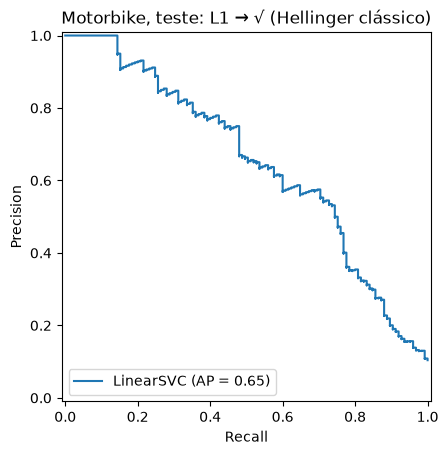

In [9]:
motorbike_val = stage_f[stage_f["categoria"] == "motorbike"]
best_variant = motorbike_val.loc[motorbike_val["AP validação"].idxmax(), "variante"]
print("Variante escolhida na validação:", best_variant)

data = load_data("motorbike", "bovw_K512_C0")
for name in ("Linear + L2 (referência)", best_variant):
    result = test_ap(data, hellinger_variants[name])
    print(f"{name:30s} AP teste = {result['ap']:.4f}")

*_, ap = displayPrecisionRecallCurve(data["y_test"], result["scores"],
                                     title=f"Motorbike, teste: {best_variant}")

# Stage G: Vary the number of training images

Treina-se com 10%, 25%, 50% e 100% do split de treino, com 3 seeds, e mede-se o AP na **validação**
(que é sempre a mesma). O subconjunto é **estratificado**: com 10% de ~900 imagens e ~10% de positivos,
uma amostra puramente aleatória podia ficar com quase nenhuma mota.

Com 100% o desvio padrão é 0: o subconjunto é sempre o treino inteiro e o SVM é determinístico.

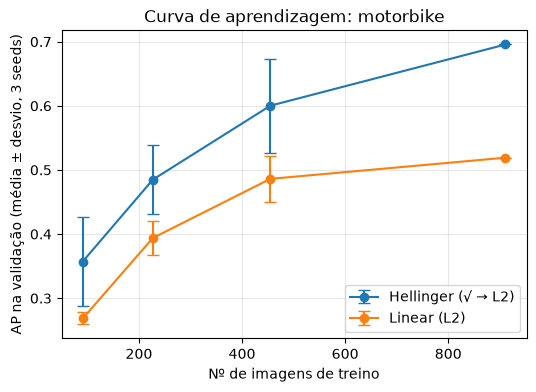

n_imagens  n_positivos  AP_média  AP_desvio
kernel             fração                                             
Hellinger (√ → L2) 0.10           91           10    0.3572     0.0698
                   0.25          227           24    0.4849     0.0534
                   0.50          455           48    0.6002     0.0732
                   1.00          911           96    0.6956     0.0000
Linear (L2)        0.10           91           10    0.2684     0.0094
                   0.25          227           24    0.3939     0.0271
                   0.50          455           48    0.4861     0.0359
                   1.00          911           96    0.5191     0.0000

In [10]:
def subsample(x, y, fraction, seed):
    if fraction >= 1:
        return x, y
    x_sub, _, y_sub, _ = train_test_split(x, y, train_size=fraction, stratify=y, random_state=seed)
    return x_sub, y_sub


category = "motorbike"
fractions = [0.10, 0.25, 0.50, 1.00]
seeds = [0, 1, 2]
kernels = {"Linear (L2)": ["l2"], "Hellinger (√ → L2)": ["sqrt", "l2"]}

data = load_data(category, "bovw_K512_C0")
rows = []
for kernel_name, steps in kernels.items():
    # A normalização é por imagem, por isso pode ser feita uma vez antes de subamostrar
    x_train = preprocess(data["x_train"], steps)
    x_val = preprocess(data["x_val"], steps)

    for fraction in fractions:
        for seed in seeds:
            x_sub, y_sub = subsample(x_train, data["y_train"], fraction, seed)
            W, b = utils.train_svm(x_sub, y_sub, C=C)
            ap = average_precision_score(data["y_val"], W @ x_val.T + b)
            rows.append({"kernel": kernel_name, "fração": fraction, "seed": seed,
                         "nº imagens treino": len(y_sub), "nº positivos": int(np.sum(y_sub > 0)), "AP validação": ap})

stage_g = pd.DataFrame(rows)
summary_g = (stage_g.groupby(["kernel", "fração"])
             .agg(n_imagens=("nº imagens treino", "first"), n_positivos=("nº positivos", "first"),
                  AP_média=("AP validação", "mean"), AP_desvio=("AP validação", "std"))
             .round(4))

fig, ax = plt.subplots(figsize=(6, 4))
for kernel_name, group in summary_g.groupby(level="kernel"):
    ax.errorbar(group["n_imagens"], group["AP_média"], yerr=group["AP_desvio"],
                marker="o", capsize=4, label=kernel_name)
ax.set_xlabel("Nº de imagens de treino")
ax.set_ylabel("AP na validação (média ± desvio, 3 seeds)")
ax.set_title(f"Curva de aprendizagem: {category}")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

summary_g

# Parte 2: VLAD e Fisher Vectors

Para comparar as três codificações de forma justa, todas passam pela mesma função `evaluate_encoding`:
1. para cada categoria, mede o AP na validação de cada variante de normalização;
2. escolhe **uma** variante por encoding: a de maior AP médio na validação (o mesmo pipeline para todas as classes);
3. avalia essa variante no teste, para cada categoria.

As encodings usam os **mesmos descritores SIFT** e os mesmos splits; só muda a codificação.

In [11]:
def evaluate_encoding(encoding, variants, block_size=None):
    val_rows, test_rows = [], []

    for category in categories:
        data = load_data(category, encoding)
        for name, steps in variants.items():
            ap, train_time, dim = validation_ap(data, steps, block_size=block_size)
            val_rows.append({"categoria": category, "variante": name, "dimensão": dim,
                             "AP validação": ap, "treino (s)": train_time})

    val_table = pd.DataFrame(val_rows)
    mean_val = val_table.groupby("variante", sort=False)["AP validação"].mean()
    best = mean_val.idxmax()
    print(f"{encoding}: variante escolhida na validação = {best} (AP médio {mean_val[best]:.4f})")

    for category in categories:
        data = load_data(category, encoding)
        result = test_ap(data, variants[best], block_size=block_size)
        test_rows.append({"categoria": category, "AP teste": result["ap"],
                          "treino final (s)": result["train_time"],
                          "inferência (ms/img)": result["inference_ms"]})

    val_pivot = val_table.pivot_table(index="variante", columns="categoria",
                                      values="AP validação", sort=False).round(4)
    return val_pivot, pd.DataFrame(test_rows).round(4), best, val_table["dimensão"].iloc[0]


summary = {}   # resultados finais de cada encoding, para a tabela comparativa

## Referência: BoVW com o mesmo procedimento

Corre-se o BoVW pela mesma função, para a comparação final usar exatamente o mesmo protocolo.

In [12]:
bovw_variants = {"L2": ["l2"], "Hellinger (√ → L2)": ["sqrt", "l2"]}
val_pivot, test_table, best, dim = evaluate_encoding("bovw_K512_C0", bovw_variants)
summary["bovw_K512_C0"] = {"variante": best, "dimensão": dim, "test": test_table}
display(val_pivot)
test_table

bovw_K512_C0: variante escolhida na validação = Hellinger (√ → L2) (AP médio 0.7393)


categoria,aeroplane,motorbike,person
variante,,,
L2,0.6236,0.5191,0.7123
Hellinger (√ → L2),0.7654,0.6956,0.7569


,categoria,AP teste,treino final (s),inferência (ms/img)
0,aeroplane,0.7414,0.1696,0.0306
1,motorbike,0.6509,0.2232,0.0296
2,person,0.7812,0.5919,0.0261


# Stage H: VLAD

O encoder já normaliza cada tile com L2 (`unnormalized=False` no `VLADEncoder`); a concatenação dos 4 tiles
não tem norma 1, por isso a variante "L2" volta a normalizar o vetor inteiro.

Variantes:
- **nenhuma**: os 4 tiles tal como vêm do encoder;
- **L2**: normalização global;
- **√ → L2**: power normalization (raiz com sinal) + L2;
- **intra → L2**: L2 de cada bloco de resíduos (um por centro) e depois L2 global (Arandjelović & Zisserman, 2013);
- **√ → intra → L2**: as duas combinadas.

O tamanho de cada bloco é a dimensão D dos descritores depois do PCA, lida do próprio encoder.
O VLFeat guarda o vetor VLAD como blocos consecutivos de D valores, um por centro.

In [13]:
vlad_encoding = "vlad_K32_C80"
vlad_words = np.load(f"data/encoders/{vlad_encoding}.npz")["words"]   # shape (K, D)
K, D = vlad_words.shape
print(f"VLAD: K = {K}, D = {D}, dimensão nominal K×D = {K * D} por tile, {4 * K * D} com 4 tiles")

vlad_variants = {
    "nenhuma": [],
    "L2": ["l2"],
    "√ → L2": ["sqrt", "l2"],
    "intra → L2": ["intra", "l2"],
    "√ → intra → L2": ["sqrt", "intra", "l2"],
}
val_pivot, test_table, best, dim = evaluate_encoding(vlad_encoding, vlad_variants, block_size=D)
summary[vlad_encoding] = {"variante": best, "dimensão": dim, "test": test_table}
display(val_pivot)
test_table

VLAD: K = 32, D = 80, dimensão nominal K×D = 2560 por tile, 10240 com 4 tiles
vlad_K32_C80: variante escolhida na validação = √ → L2 (AP médio 0.8125)


categoria,aeroplane,motorbike,person
variante,,,
nenhuma,0.7917,0.6658,0.7786
L2,0.7916,0.6623,0.7894
√ → L2,0.7994,0.8154,0.8229
intra → L2,0.7862,0.7715,0.7960
√ → intra → L2,0.7660,0.7962,0.8190


,categoria,AP teste,treino final (s),inferência (ms/img)
0,aeroplane,0.7528,0.6842,0.123
1,motorbike,0.7490,1.1887,0.123
2,person,0.7817,4.4345,0.134


# Stage I: Fisher Vector

A GMM foi ajustada só com descritores de treino (`train.py`, ramo `fv`, com `learn_gmm`).
A função `fisher_vector` do scikit-image usa `improved=False` por omissão (sem raiz nem L2),
por isso:
- **√ → L2** corresponde ao **Improved Fisher Vector** (Perronnin, Sánchez & Mensink, 2010).

Nota: o scikit-image também inclui o gradiente em relação aos pesos da mistura (K valores por tile),
por isso a dimensão real é um pouco maior do que 2·K·D.

In [14]:
fv_encoding = "fv_K32_C80"
fv_cfg = np.load(f"data/encoders/{fv_encoding}.npz")
K_fv, D_fv = fv_cfg["means"].shape
print(f"FV: K = {K_fv}, D = {D_fv}, dimensão nominal 2·K·D = {2 * K_fv * D_fv} por tile")

fv_variants = {
    "nenhuma": [],
    "L2": ["l2"],
    "√ → L2 (Improved FV)": ["sqrt", "l2"],
}
val_pivot, test_table, best, dim = evaluate_encoding(fv_encoding, fv_variants)
summary[fv_encoding] = {"variante": best, "dimensão": dim, "test": test_table}
print(f"Dimensão real: {dim} ({dim // 4} por tile)")
display(val_pivot)
test_table

FV: K = 32, D = 80, dimensão nominal 2·K·D = 5120 por tile
fv_K32_C80: variante escolhida na validação = √ → L2 (Improved FV) (AP médio 0.8005)
Dimensão real: 20608 (5152 por tile)


categoria,aeroplane,motorbike,person
variante,,,
nenhuma,0.7580,0.7656,0.7881
L2,0.7445,0.8049,0.7952
√ → L2 (Improved FV),0.7469,0.8131,0.8415


,categoria,AP teste,treino final (s),inferência (ms/img)
0,aeroplane,0.7730,2.5533,0.0858
1,motorbike,0.8061,3.0571,0.0674
2,person,0.8189,9.4296,0.0741


# Comparação BoVW vs VLAD vs FV

**Tempo de extração:** mede-se em 10 imagens de teste, separando
(1) o SIFT denso, que é igual para as três codificações, e
(2) a codificação (atribuição + agregação, nos 4 tiles). Não inclui ler a imagem do disco nem carregar o encoder.

**Armazenamento:** tamanho de um vetor em float32 (4 bytes por valor) e tamanho real dos ficheiros `.npz` comprimidos no disco.

In [15]:
from src.features import computeFeatures

sample_names = load_data("motorbike", "bovw_K512_C0")["names_test"][:10]
sample_paths = [f"data/images/{name}.jpg" for name in sample_names]

start = time.perf_counter()
features = [computeFeatures(path) for path in sample_paths]
sift_ms = (time.perf_counter() - start) * 1000 / len(features)
print(f"SIFT denso: {sift_ms:.0f} ms por imagem")

encoding_ms = {}
for encoding in summary:
    encoder = encoders.ImageEncoder(f"data/encoders/{encoding}.npz")
    start = time.perf_counter()
    for keypoints, descriptors, image_size in features:
        encoder.encode_tiling(keypoints, descriptors, image_size)
    encoding_ms[encoding] = (time.perf_counter() - start) * 1000 / len(features)
    print(f"{encoding:15s} codificação: {encoding_ms[encoding]:.0f} ms por imagem")

SIFT denso: 198 ms por imagem
bovw_K512_C0    codificação: 154 ms por imagem
vlad_K32_C80    codificação: 87 ms por imagem
fv_K32_C80      codificação: 177 ms por imagem


In [16]:
def disk_size_per_image_kb(encoding):
    folder = f"data/encodings/{encoding}"
    total_bytes, total_images = 0, 0
    for file_name in os.listdir(folder):
        path = os.path.join(folder, file_name)
        total_bytes += os.path.getsize(path)
        total_images += len(np.load(path)["file_names"])
    return total_bytes / total_images / 1024


rows = []
for encoding, result in summary.items():
    test_table = result["test"]
    row = {"encoding": encoding, "variante (validação)": result["variante"], "dimensão": result["dimensão"]}
    for _, r in test_table.iterrows():
        row[f"AP {r['categoria']}"] = r["AP teste"]
    row["mAP teste"] = round(test_table["AP teste"].mean(), 4)
    row["treino SVM médio (s)"] = round(test_table["treino final (s)"].mean(), 2)
    row["inferência (ms/img)"] = round(test_table["inferência (ms/img)"].mean(), 4)
    row["codificação (ms/img)"] = round(encoding_ms.get(encoding, np.nan), 1)
    row["vetor float32 (KB)"] = round(result["dimensão"] * 4 / 1024, 1)
    row["disco .npz (KB/img)"] = round(disk_size_per_image_kb(encoding), 1)
    rows.append(row)

comparison = pd.DataFrame(rows)
comparison

,encoding,variante (validação),dimensão,AP aeroplane,AP motorbike,AP person,mAP teste,treino SVM médio (s),inferência (ms/img),codificação (ms/img),vetor float32 (KB),disco .npz (KB/img)
0,bovw_K512_C0,Hellinger (√ → L2),2048,0.7414,0.6509,0.7812,0.7245,0.33,0.0288,153.8,8.0,2.2
1,vlad_K32_C80,√ → L2,10240,0.7528,0.7490,0.7817,0.7612,2.10,0.1267,86.5,40.0,36.5
2,fv_K32_C80,√ → L2 (Improved FV),20608,0.7730,0.8061,0.8189,0.7993,5.01,0.0758,176.9,80.5,153.6
